# 06 · A fair label: does uneven satellite coverage distort the results?

**The worry.** Our flood label says a small cell (about 550 m) is *flooded* in a season if **at least 2 satellite passes** saw water there. But the seasons were not photographed equally: the study area got about 10 looks in 2024, **22 in 2025** and 11 in 2026. More looks means more chances to reach 2. So a season can look "wetter" only because it was photographed more often.

An everyday comparison: count how many days it rained by looking out of the window. If you look 22 times one month and 10 times the next, the first month will seem rainier even if the weather was the same.

**The idea.** Put every cell and season on the same footing: *what would the label have been if every cell had been photographed exactly 5 times?* We can work that out from two numbers we already saved for every cell, the number of looks and the number of wet looks, with no new downloads.

**Steps**
1. How the equal-coverage label works, with a small example
2. Build it for every cell and season
3. Did it remove the coverage effect?
4. Rerun the key results with the fair label
5. What changed, and what did not

**Inputs.** The per-cell counts saved by notebook 02 (on the data disk) and `data_small/model_table.parquet`.
**Outputs.** `data_small/labels_equalised.parquet` (small, in git), tables in `results/` starting with `y`, and one figure. If the counts on the data disk are missing, steps 3 to 5 still run from the saved small file.

## Setup

In [1]:
import sys, time, warnings
from pathlib import Path
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from config import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import hypergeom
from scipy.spatial import cKDTree
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, GroupKFold
from src.flood_utils import rmse, savefig

warnings.filterwarnings("ignore")
FAST = False
N_TREES = 60 if FAST else 300
M_LOOKS = 5            # the common number of looks (the study area requires at least 5 on average)
M_CHECK = 8            # a second choice, to see whether the answer depends on it
F = FINE_FACTOR
T0 = time.time()

df = pd.read_parquet(SMALL_DIR / "model_table.parquet")
FEATURES = pd.read_csv(RESULTS_DIR / "feature_dictionary.csv")["feature"].tolist()
print(df.shape)

(11922, 38)


## Step 1 · How the equal-coverage label works

For one small cell in one season we know two numbers: **n**, how many passes photographed it, and **c**, how many of those saw water.

Now imagine drawing only **5** of its n looks at random, like drawing 5 cards from a deck of n cards in which c are marked "wet". The **equal-coverage label** is the chance that at least 2 of the 5 drawn cards are wet. It is a number between 0 and 1 instead of a yes or no.

This is a standard counting problem (the *hypergeometric* distribution), so no simulation is needed. The table shows what it does to a few example cells.

In [2]:
def chance_two_wet(n, c, m):
    """Chance of at least 2 wet looks when m of the n looks are drawn at random and c of the n are wet."""
    n, c = np.asarray(n), np.asarray(c)
    n = np.maximum(n, c)                      # safety: wet looks can never exceed looks
    m_eff = np.minimum(m, n)                  # a cell with fewer than m looks keeps all of them
    p = 1.0 - hypergeom.cdf(1, n, c, m_eff)
    return np.clip(np.where(c >= 2, p, 0.0), 0, 1)        # fewer than 2 wet looks can never reach 2

ex = pd.DataFrame({"looks n": [5, 10, 22, 22, 22, 10, 4], "wet looks c": [2, 2, 2, 4, 9, 5, 2]})
ex["original label (c >= 2)"] = (ex["wet looks c"] >= 2).astype(int)
ex[f"equal-coverage label ({M_LOOKS} looks)"] = chance_two_wet(ex["looks n"].values, ex["wet looks c"].values, M_LOOKS).round(2)
ex

,looks n,wet looks c,original label (c >= 2),equal-coverage label (5 looks)
0,5,2,1,1.00
1,10,2,1,0.22
2,22,2,1,0.04
3,22,4,1,0.21
4,22,9,1,0.71
5,10,5,1,0.90
6,4,2,1,1.00


**How to read this.** A cell seen wet twice in 5 looks keeps its label of 1. A cell seen wet twice in **22** looks counted as fully flooded under the original rule, but with only 5 looks it would have reached "2 wet" only about 1 time in 25, so its fair label is about 0.04. Water that is there most of the time (9 wet of 22) still scores close to 1. So the fair label mostly discounts **brief water that was only caught because a season was photographed very often**.

## Step 2 · Build it for every cell and season

Notebook 02 saved, for every small cell, the wet-look count and the look count of each season. We apply the formula to every cell, average the 100 small cells of each 5 km square, and remove permanent water exactly as before.

In [3]:
eq_file = SMALL_DIR / "labels_equalised.parquet"
have_counts = all((INTERIM / f"label_flood_count_{y}.npy").exists() and (INTERIM / f"label_hull_count_{y}.npy").exists() for y in YEARS)

if have_counts:
    water = np.load(INTERIM / "jrc_water_frac_5km.npy")
    H, W = water.shape
    sq = df[df.season == YEARS[0]][["cell_id", "row", "col"]]
    parts = []
    for y in YEARS:
        c = np.load(INTERIM / f"label_flood_count_{y}.npy").astype(int)
        n = np.load(INTERIM / f"label_hull_count_{y}.npy").astype(int)
        t = sq.copy(); t["season"] = y
        for m in (M_LOOKS, M_CHECK):
            table = np.zeros((int(max(n.max(), c.max())) + 1,) * 2)        # every (n, c) pair once, then look up
            nn, cc = np.meshgrid(np.arange(table.shape[0]), np.arange(table.shape[0]), indexing="ij")
            ok = cc <= nn
            table[ok] = chance_two_wet(nn[ok], cc[ok], m)
            fine = table[np.maximum(n, c), c]
            coarse = fine.reshape(H, F, W, F).mean(axis=(1, 3))
            t[f"flooded_eq{m}"] = np.clip(coarse - water, 0, None)[t.row.values, t.col.values].round(4)
        t["fine_cells_under_5_looks"] = (n < M_LOOKS).reshape(H, F, W, F).mean(axis=(1, 3))[t.row.values, t.col.values].round(3)
        parts.append(t.drop(columns=["row", "col"]))
        print(y, "done")
    eq = pd.concat(parts, ignore_index=True)
    eq.to_parquet(eq_file, index=False)
else:
    print("per-cell counts not found on the data disk: using the saved file")
    eq = pd.read_parquet(eq_file)

df = df.merge(eq, on=["cell_id", "season"])
ORIG, FAIR, FAIR2 = "flooded_frac", f"flooded_eq{M_LOOKS}", f"flooded_eq{M_CHECK}"
print(df.shape, "| share of small cells with fewer than 5 looks:", df.groupby("season").fine_cells_under_5_looks.mean().round(3).to_dict())

2024 done
2025 done
2026 done
(11922, 41) | share of small cells with fewer than 5 looks: {2024: 0.002, 2025: 0.001, 2026: 0.003}


**What to check:** three "done" lines. Small cells with fewer than 5 looks keep their original rule (there is nothing to thin), so that share should be small.

## Step 3 · Did it remove the coverage effect?

Three checks, each comparing the **original** label with the **fair** one.

**3a. Season totals.** 2025 had twice the looks and the most flooding. Does 2025 still stand out?

In [4]:
a3 = df.groupby("season").agg(looks=("times_photographed", "mean"), original=(ORIG, "mean"),
                              fair_5_looks=(FAIR, "mean"), fair_8_looks=(FAIR2, "mean")).round(4)
a3["original vs 3-season mean"] = (a3.original / a3.original.mean()).round(2)
a3["fair vs 3-season mean"] = (a3.fair_5_looks / a3.fair_5_looks.mean()).round(2)
a3.to_csv(RESULTS_DIR / "y1_season_totals.csv"); a3

,looks,original,fair_5_looks,fair_8_looks,original vs 3-season mean,fair vs 3-season mean
season,,,,,,
2024,9.8784,0.0315,0.0201,0.0266,0.95,1.00
2025,21.6397,0.0401,0.0236,0.0291,1.21,1.17
2026,11.0056,0.0277,0.0167,0.0217,0.84,0.83


**How to read this.** The last two columns put each season against the three-season average (1.00 = average). If 2025 moves toward 1.00 under the fair label, part of its "extra flooding" was extra photographs. The fair label is lower overall, because it counts brief water only in proportion to how likely 5 looks would catch it. What matters is the *comparison between seasons*, not the level.

**3b. Square by square.** For each square, take *this season minus the average of the other two* for both the flooding (the anomaly the models try to explain) and the number of looks. If squares that got **more looks than usual** also show **more flooding than usual**, the anomaly is partly a camera effect. A fair label should weaken that link.

In [5]:
def anomaly(col):
    p = df.pivot(index="cell_id", columns="season", values=col)
    return pd.concat({s: p[s] - p[[o for o in YEARS if o != s]].mean(axis=1) for s in YEARS}).rename(col)

an = pd.concat([anomaly(ORIG), anomaly(FAIR), anomaly("times_photographed")], axis=1).reset_index(names=["season", "cell_id"])
wet = an.cell_id.isin(df[df[ORIG] > 0].cell_id.unique())                    # squares that flooded at least once
rows = []
for s in YEARS:
    g = an[(an.season == s) & wet]
    rows.append(dict(season=s, squares=len(g),
                     link_original=g[ORIG].corr(g["times_photographed"], method="spearman"),
                     link_fair=g[FAIR].corr(g["times_photographed"], method="spearman"),
                     mean_abs_anomaly_original=g[ORIG].abs().mean(), mean_abs_anomaly_fair=g[FAIR].abs().mean()))
a3b = pd.DataFrame(rows).round(3); a3b.to_csv(RESULTS_DIR / "y2_anomaly_vs_looks.csv", index=False); a3b

,season,squares,link_original,link_fair,mean_abs_anomaly_original,mean_abs_anomaly_fair
0,2024,1300,-0.135,-0.190,0.054,0.035
1,2025,1300,0.236,0.138,0.064,0.036
2,2026,1300,0.401,0.324,0.082,0.051


**How to read this.** `link` is a rank correlation between "more looks than usual" and "more flooding than usual", over squares that flooded at least once. 0 means no link; a clearly positive value means the anomaly follows the camera. Compare `link_original` with `link_fair`. A caution: looks and real flooding are not independent, because satellites are often pointed at areas that are flooding, so some link can remain for honest reasons.

**3c. The map.** Where did the fair label change the 2025 picture?

saved /home/tb3203/thailand-flood-ml/figures/fig_fair_label_2025.png


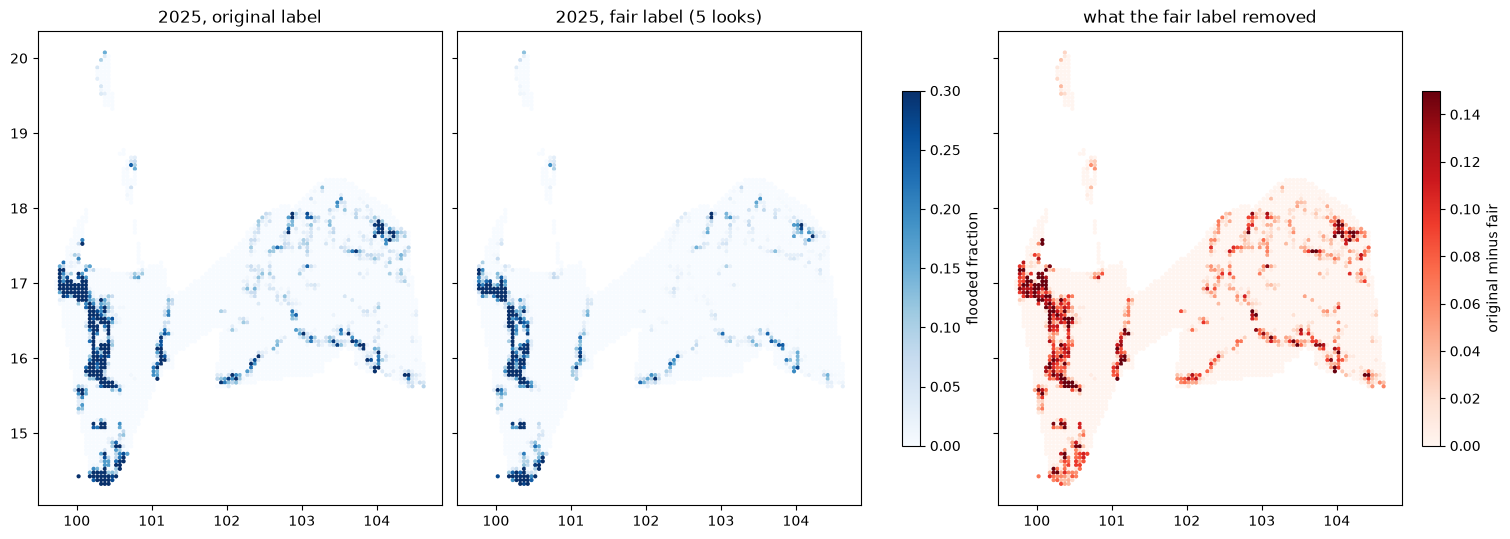

rank correlation between the two labels, per season: {2024: np.float64(0.973), 2025: np.float64(0.967), 2026: np.float64(0.961)}


In [6]:
g = df[df.season == 2025]
fig, ax = plt.subplots(1, 3, figsize=(15, 6), sharey=True, layout="constrained")
for a, col, title in zip(ax[:2], [ORIG, FAIR], ["2025, original label", f"2025, fair label ({M_LOOKS} looks)"]):
    sc = a.scatter(g.lon, g.lat, c=g[col], s=4, cmap="Blues", vmin=0, vmax=0.3); a.set_title(title); a.set_aspect("equal")
fig.colorbar(sc, ax=ax[:2], shrink=0.6, label="flooded fraction")
sc2 = ax[2].scatter(g.lon, g.lat, c=g[ORIG] - g[FAIR], s=4, cmap="Reds", vmin=0, vmax=0.15)
ax[2].set_title("what the fair label removed"); ax[2].set_aspect("equal")
fig.colorbar(sc2, ax=ax[2], shrink=0.6, label="original minus fair")
savefig(fig, "fig_fair_label_2025", FIG_DIR); plt.show()
print("rank correlation between the two labels, per season:",
      {s: round(df[df.season == s][[ORIG, FAIR]].corr(method="spearman").iloc[0, 1], 3) for s in YEARS})

**What to check:** the two maps should show the same places (a high correlation), with the fair one paler where flooding was brief. The third panel shows where water was counted mainly because of frequent looks.

## Step 4 · Rerun the key results with the fair label

Same splits, same baselines, same models and the same tuning procedure as notebook 04. The only change is the label. For the season hold-out we report the skill against **usual**; for the region hold-out, against **one constant**. We also include **usual × one number** from notebook 05, the simplest model that could beat usual.

In [7]:
def make_regions(cells, level="basin_l5", min_size=300):
    c = cells.groupby(level).agg(n=("cell_id", "size"), lat=("lat", "mean"), lon=("lon", "mean"))
    big = c[c.n >= min_size]
    if len(big) < 3: big = c.nlargest(3, "n")
    mapping = {}
    for b, r in c.iterrows():
        d = (big.lat - r.lat) ** 2 + ((big.lon - r.lon) * np.cos(np.radians(r.lat))) ** 2
        mapping[b] = b if b in big.index else d.idxmin()
    names = {b: f"R{i + 1}" for i, b in enumerate(big.sort_values(["lon", "lat"]).index)}
    return cells[level].map(mapping).map(names)

cells = df[df.season == YEARS[0]][["cell_id", "lat", "lon", "basin_l5"]].reset_index(drop=True)
cells["basin_l5"] = cells["basin_l5"].astype(int)
cells["region"] = make_regions(cells)
df = df.merge(cells[["cell_id", "region"]], on="cell_id")
REGIONS = sorted(cells.region.unique(), key=lambda r: int(r[1:]))
XY = np.c_[cells.lon * 111.32 * np.cos(np.radians(cells.lat)), cells.lat * 110.57]
tree = cKDTree(XY)
def buffer_cells(ids, km=10):
    near = tree.query_ball_point(XY[cells.cell_id.isin(ids).values], r=km)
    return set(cells.cell_id.values[np.unique(np.concatenate(near))]) - set(ids)

MODELS = {"ridge":  (Pipeline([("scale", StandardScaler()), ("model", Ridge())]),
                     {"model__alpha": [1, 10, 100, 1_000, 10_000, 100_000]}),
          "forest": (RandomForestRegressor(n_estimators=N_TREES, n_jobs=-1, random_state=RANDOM_STATE),
                     {"min_samples_leaf": [5, 20, 50, 100, 200], "max_features": [0.33, 0.66]} if not FAST else
                     {"min_samples_leaf": [20], "max_features": [0.5]})}
def tune_and_fit(name, X, y, groups):
    est, grid = MODELS[name]
    return GridSearchCV(est, grid, cv=GroupKFold(min(4, len(np.unique(groups)))),
                        scoring="neg_root_mean_squared_error").fit(X, y, groups=groups).best_estimator_
def skill(obs, pred, ref):
    return 1 - rmse(obs, pred) ** 2 / rmse(obs, ref) ** 2

def run_all(label):
    piv = df.pivot(index="cell_id", columns="season", values=label)
    rows = []
    for s in YEARS:                                              # A: season hold-out
        a, b = [o for o in YEARS if o != s]
        tr, te = df[df.season.isin([a, b])].copy(), df[df.season == s].copy()
        tr["usual"] = np.where(tr.season == a, tr.cell_id.map(piv[b]), tr.cell_id.map(piv[a]))
        te["usual"] = te.cell_id.map(piv[[a, b]].mean(axis=1)).values
        obs, usual = te[label].values, te["usual"].values
        k = float((tr[label] * tr["usual"]).sum() / (tr["usual"] ** 2).sum())
        rows.append(dict(scheme="A season", fold=s, method="RMSE of usual", value=rmse(obs, usual)))
        rows.append(dict(scheme="A season", fold=s, method="RMSE of never flooded", value=rmse(obs, 0 * obs)))
        rows.append(dict(scheme="A season", fold=s, method="skill: usual x one number", value=skill(obs, k * usual, usual)))
        for m in MODELS:
            est = tune_and_fit(m, tr[FEATURES + ["usual"]], tr[label] - tr["usual"], tr["region"])
            p = np.clip(usual + est.predict(te[FEATURES + ["usual"]]), 0, 1)
            rows.append(dict(scheme="A season", fold=s, method=f"skill: {m}", value=skill(obs, p, usual)))
    for r in REGIONS:                                            # B: region hold-out
        ids = set(cells.cell_id[cells.region == r]); drop = buffer_cells(ids)
        tr, te = df[~df.cell_id.isin(ids | drop)], df[df.cell_id.isin(ids)]
        const = np.full(len(te), tr[label].mean())
        for m in MODELS:
            p = np.clip(tune_and_fit(m, tr[FEATURES], tr[label], tr["region"]).predict(te[FEATURES]), 0, 1)
            rows.append(dict(scheme="B region", fold=r, method=f"skill: {m}", value=skill(te[label], p, const)))
    print(label, f"done ({time.time() - T0:.0f} s)")
    return pd.DataFrame(rows).assign(label=label)

res = pd.concat([run_all(ORIG), run_all(FAIR), run_all(FAIR2)], ignore_index=True)
res["label"] = res["label"].map({ORIG: "original", FAIR: f"fair ({M_LOOKS} looks)", FAIR2: f"fair ({M_CHECK} looks)"})
res.to_csv(RESULTS_DIR / "y3_results_by_label.csv", index=False)

flooded_frac done (262 s)
flooded_eq5 done (534 s)
flooded_eq8 done (799 s)


In [8]:
def show(scheme):
    t = res[res.scheme == scheme].pivot_table(index=["method", "label"], columns="fold", values="value", sort=False).round(3)
    return t.sort_index(level=0, sort_remaining=False)

print("A. Season hold-out. Skill is measured against 'usual' (0 = same as usual, above 0 = better)")
display(show("A season"))
print("B. Region hold-out. Skill is measured against one constant")
display(show("B region"))

A. Season hold-out. Skill is measured against 'usual' (0 = same as usual, above 0 = better)


fold                                       2024   2025   2026
method                    label                              
RMSE of never flooded     original        0.108  0.124  0.100
                          fair (5 looks)  0.078  0.089  0.072
                          fair (8 looks)  0.095  0.102  0.086
RMSE of usual             original        0.050  0.055  0.072
                          fair (5 looks)  0.037  0.038  0.052
                          fair (8 looks)  0.042  0.042  0.060
skill: forest             original       -0.415 -0.385  0.116
                          fair (5 looks) -0.443 -0.393  0.070
                          fair (8 looks) -0.327 -0.333  0.060
skill: ridge              original       -0.139 -0.339  0.063
                          fair (5 looks)  0.036 -0.141  0.063
                          fair (8 looks)  0.016 -0.129  0.055
skill: usual x one number original       -0.057 -0.442  0.125
                          fair (5 looks) -0.045 -0.521  0.122
                          fair (8 looks) -0.129 -0.469  0.107

B. Region hold-out. Skill is measured against one constant


fold                             R1     R2     R3     R4
method        label                                     
skill: forest original        0.285  0.667  0.276  0.382
              fair (5 looks)  0.197  0.640  0.225  0.366
              fair (8 looks)  0.249  0.658  0.268  0.398
skill: ridge  original        0.226  0.455  0.126  0.095
              fair (5 looks)  0.143  0.408  0.105  0.100
              fair (8 looks)  0.172  0.433  0.119  0.107

**How to read this.** For each method there are three rows: the original label and the fair label with 5 and with 8 looks. The "original" rows should repeat notebooks 04 and 05 (a quick check that nothing else changed).

- **Season hold-out.** Look first at *RMSE of usual*: if it drops a lot under the fair label, the seasons now resemble each other more, which means part of the season-to-season difference was coverage. Then look at the skill rows: do ridge, forest or *usual × one number* beat usual (above 0) in any season, and is the pattern the same as before?
- **Region hold-out.** Our solid positive result. It should stay clearly above 0 in every region. If it does, "terrain and rivers show where water collects" does not depend on how the label treats coverage.
- **5 looks or 8 looks.** If the two fair rows agree, the choice of 5 did not drive the answer.

## Step 5 · What changed, and what did not

A compact side-by-side view for the paper.

In [9]:
pick = res[res.label != f"fair ({M_CHECK} looks)"]
side = pick.pivot_table(index=["scheme", "method", "fold"], columns="label", values="value", sort=False).round(3)
side["change"] = (side[f"fair ({M_LOOKS} looks)"] - side["original"]).round(3)
side.to_csv(RESULTS_DIR / "y4_original_vs_fair.csv")
side

label                                    original  fair (5 looks)  change
scheme   method                    fold                                  
A season RMSE of usual             2024     0.050           0.037  -0.013
                                   2025     0.055           0.038  -0.017
                                   2026     0.072           0.052  -0.020
         RMSE of never flooded     2024     0.108           0.078  -0.030
                                   2025     0.124           0.089  -0.035
                                   2026     0.100           0.072  -0.028
         skill: usual x one number 2024    -0.057          -0.045   0.012
                                   2025    -0.442          -0.521  -0.079
                                   2026     0.125           0.122  -0.003
         skill: ridge              2024    -0.139           0.036   0.175
                                   2025    -0.339          -0.141   0.198
                                   2026     0.063           0.063   0.000
         skill: forest             2024    -0.415          -0.443  -0.028
                                   2025    -0.385          -0.393  -0.008
                                   2026     0.116           0.070  -0.046
B region skill: ridge              R1       0.226           0.143  -0.083
                                   R2       0.455           0.408  -0.047
                                   R3       0.126           0.105  -0.021
                                   R4       0.095           0.100   0.005
         skill: forest             R1       0.285           0.197  -0.088
                                   R2       0.667           0.640  -0.027
                                   R3       0.276           0.225  -0.051
                                   R4       0.382           0.366  -0.016

### What this label can and cannot fix

- **It fixes** the unequal *number* of looks between seasons and places.
- **It cannot fix** *when* the looks happened. Satellites are often tasked during floods, so looks are not spread evenly through the season, and 5 looks in the peak week are not the same as 5 looks spread over three months.
- **The look count is itself approximate.** GISTDA publishes flood polygons, not the outline of each image, so "looks" are counted from the hull around each pass's polygons (notebook 02).
- **Cells with fewer than 5 looks** keep the original rule.

These points belong in the limitations section whatever the tables above show.

```bash
cd ~/thailand-flood-ml
git add -A
git commit -m "Notebook 06: equal-coverage label and rerun of key results"
git push
```

In [10]:
print(f"Total run time: {(time.time() - T0) / 60:.1f} min")

Total run time: 13.3 min
